<a href="https://colab.research.google.com/github/SahanaV96111/DAV/blob/main/Lab5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv(r"/content/StudentsPerformance.csv")
print('First 5 rows of the dataset:')
print(df.head())
print('\nDataset shape:')
print(df.shape)

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(r"/content/StudentsPerformance.csv")
print('First 5 rows of the dataset:')
print(df.head())
print('\nDataset shape:')
print(df.shape)

# Extract column data first, then print the count
data = df["math score"].dropna()
print("\nNumber of math score values:", len(data))

# IQR Calculation
Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("\nIQR METHOD ")

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)


First 5 rows of the dataset:
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  

Dataset shape:
(1000, 8)
First 5 rows of the dataset:
   gender race/ethnicity parental level of education         lunch  \
0  fe

In [ ]:
iqr_outliers = data[(data < lower_limit) | (data > upper_limit)]
print("NUmber of IQR outliers:", len(iqr_outliers))


NUmber of IQR outliers: 8


In [ ]:
mean = data.mean()
std = data.std()
df["Z_score"] = (df["math score"] - mean) / std

z_outliers = df[abs(df["Z_score"]) > 3]
print("\nZ-SCORE METHOD:")
print("Mean:", mean)
print("Standard DEviation:", std)

df["math_score_treated"] = df["math score"].clip(lower=lower_limit, upper=upper_limit)
print("Treatment method: Capping using IQR limit")

print("\nNumber of Z-score outliers:", len(z_outliers))


Z-SCORE METHOD:
Mean: 66.089
Standard DEviation: 15.163080096009468
Treatment method: Capping using IQR limit

Number of Z-score outliers: 4


In [ ]:
comparison = df[["math score", "math_score_treated"]]
print(comparison.head(20))

    math score  math_score_treated
0           72                  72
1           69                  69
2           90                  90
3           47                  47
4           76                  76
5           71                  71
6           88                  88
7           40                  40
8           64                  64
9           38                  38
10          58                  58
11          40                  40
12          65                  65
13          78                  78
14          50                  50
15          69                  69
16          88                  88
17          18                  27
18          46                  46
19          54                  54


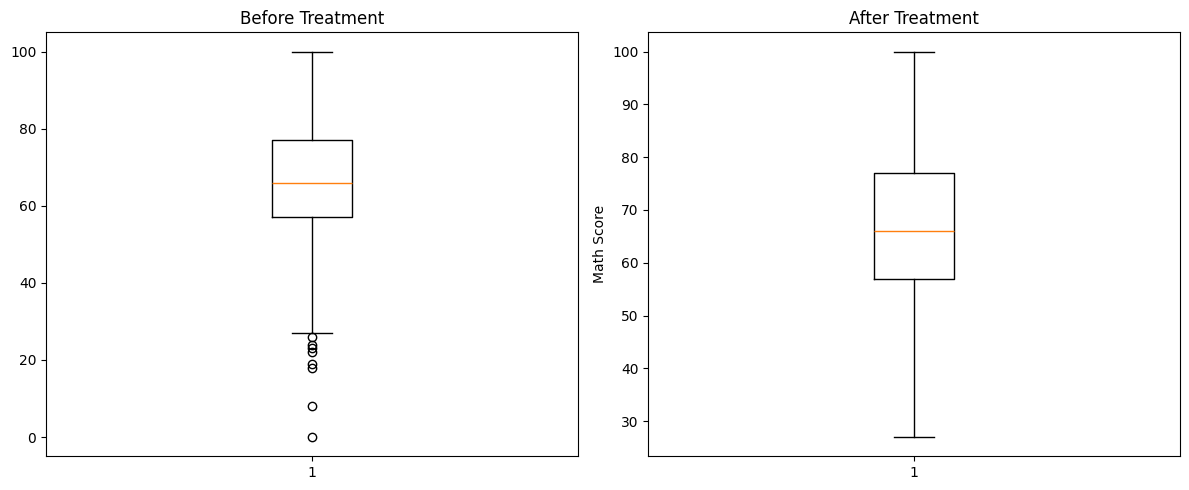

In [ ]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.boxplot(df["math score"].dropna())
plt.title("Before Treatment")
plt.subplot(1, 2, 2)
plt.boxplot(df["math_score_treated"].dropna())
plt.title("After Treatment")
plt.ylabel("Math Score")
plt.tight_layout()
plt.show()
